# Representações Posicionais em Transformers

### 1. Configure um ambiente no Google Colab com TensorFlow, Keras e keras_hub. Carregue um modelo BERT (bert_base_en_uncased) e seu respectivo pré-processador. Explore resumidamente a arquitetura e identifique os componentes responsáveis pela geração das representações de entrada.

In [1]:
import tensorflow as tf
import keras_hub
import matplotlib.pyplot as plt
import numpy as np

I0000 00:00:1795469647.770354   17661 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795469647.808301   17661 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795469648.744382   17661 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
bert = keras_hub.models.BertBackbone.from_preset("bert_base_en_uncased")
preprocessor = keras_hub.models.BertTextClassifierPreprocessor.from_preset("bert_base_en_uncased", sequence_length=16)

W0000 00:00:1795469650.683167   17661 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


O modelo e o pré-processador foram carregados, agora vamos explorar a arquitetura do `bert_base_en_uncased`

In [3]:
config = bert.get_config()

In [4]:
for label, key in [
    ("# blocos do encoder", "num_layers"),
    ("# cabeças de self-attention por bloco", "num_heads"),
    ("Dimensão oculta", "hidden_dim"),
    ("Dimensão intermediária da FFN", "intermediate_dim"),
    ("Comprimento máximo de uma sequência", "max_sequence_length"),
]:
    print(f"{label}: {config[key]}")

# blocos do encoder: 12
# cabeças de self-attention por bloco: 12
Dimensão oculta: 768
Dimensão intermediária da FFN: 3072
Comprimento máximo de uma sequência: 512


O `bert_base_en_uncased` tem **12 blocos**, cada bloco tem **12 heads de self-attention** e uma rede feed-forward com dimensão intermediária **3072**. A dimensão oculta é **768**, ou seja, cada posição é representada por um vetor de 768 valores na entrada e na saída de cada bloco.

Pela [documentação do pré-processador](https://keras.io/keras_hub/api/models/bert/bert_text_classifier_preprocessor/), o pré-processador separa o texto em tokens WordPiece, acrescenta os tokens especiais `[CLS]` e `[SEP]`, completa a sequência com `[PAD]` quando necessário e devolve `token_ids`, `segment_ids` e `padding_mask`. Aqui, `sequence_length=16` fixa o comprimento da saída do pré-processador. A tabela posicional do modelo comporta **512 posições**, de 0 a 511.

In [5]:
print("Tabelas de embeddings (# linhas, dimensão do vetor)\n")
for name in ("token_embedding", "position_embedding", "segment_embedding"):
    layer = bert.get_layer(name)
    print(f"{name}: {tuple(layer.weights[0].shape)}")

Tabelas de embeddings (# linhas, dimensão do vetor)

token_embedding: (30522, 768)
position_embedding: (512, 768)
segment_embedding: (2, 768)


A camada `token_embedding` busca um vetor de 768 valores pelo ID do token. A tabela tem 30.522 linhas, uma para cada token do vocabulário.

O `position_embedding` usa o índice absoluto do token na sequência, começando em zero. O preset configura `max_sequence_length=512`, então a tabela tem uma linha aprendida para cada posição de 0 a 511. Com `sequence_length=16` no pré-processador, o BERT usa as linhas de 0 a 15 para montar os vetores de entrada. Esse comprimento inclui os tokens especiais e, quando necessário, o preenchimento. No pré-treinamento original, o BERT usou sequências de comprimento 512 nos 10% finais dos passos, quando aprendeu os embeddings das posições mais longas.

O `segment_embedding` informa a qual trecho cada token pertence quando o BERT recebe um par como `[CLS] A [SEP] B [SEP]`. O segmento A usa o ID 0 e o segmento B usa o ID 1. Essa informação foi usada no pré-treinamento original do BERT para a tarefa de *Next Sentence Prediction* (NSP). Em metade dos exemplos, B era o trecho que vinha logo depois de A no corpus. Na outra metade, B era um trecho sorteado. O ID 1 indicava que o token pertencia a B em ambos os casos. O modelo usava a representação contextualizada de `[CLS]` para prever se B era a próxima sentença ou não. Neste trabalho, cada frase forma uma entrada independente, então o BERT soma o mesmo vetor de segmento 0 aos tokens válidos de ambas.

In [6]:
for name in ("embeddings_add", "embeddings_layer_norm", "embeddings_dropout"):
    layer = bert.get_layer(name)
    print(f"{layer.name} ({type(layer).__name__}): {tuple(layer.output.shape)}")

print(f"\nEixo da normalização: {bert.get_layer('embeddings_layer_norm').axis}")
print(f"Taxa de dropout: {bert.get_layer('embeddings_dropout').rate:.0%}")

embeddings_add (Add): (None, None, 768)
embeddings_layer_norm (LayerNormalization): (None, None, 768)
embeddings_dropout (Dropout): (None, None, 768)

Eixo da normalização: [-1]
Taxa de dropout: 10%


Então, para um token de ID $t$ na posição $p$ e no segmento $s$, a camada `embeddings_add` soma os três vetores elemento a elemento.

$$
\mathbf{x}_p = \mathbf{E}_{\mathrm{token}}[t] + \mathbf{E}_{\mathrm{pos}}[p] + \mathbf{E}_{\mathrm{seg}}[s]
$$

A camada `embeddings_layer_norm` normaliza a soma usando a média e a variância dos 768 valores de cada posição. Em seguida, `embeddings_dropout` zera aleatoriamente componentes do vetor em modo de treinamento, com probabilidade de 10% nesse preset. Em inferência, o dropout fica desativado. O vetor resultante alimenta o primeiro bloco Transformer.


In [7]:
mask_input = bert.get_layer("padding_mask")
print(f"\n{mask_input.name} ({type(mask_input).__name__}): {tuple(mask_input.output.shape)}")

mask_example = preprocessor(tf.constant(["Hello world!"]))["padding_mask"]
print("Máscara para 'Hello world!':", mask_example[0].numpy())


padding_mask (InputLayer): (None, None)
Máscara para 'Hello world!': [ True  True  True  True  True False False False False False False False
 False False False False]


A entrada `padding_mask` marca com `True` as posições válidas e com `False` as posições inseridas para completar a sequência. O BERT passa essa máscara em cada bloco Transformer. Assim, no self-attention, os tokens válidos podem usar outros tokens válidos como contexto e ignoram as posições de preenchimento.

---

### 2. Utilize o modelo para processar as sentenças abaixo:

- “The developer wrote the code with the new keyboard.”;
- “The developer wrote the code with the new mouse.”
  
### Apresente os tokens produzidos pelo pré-processador e obtenha as representações de entrada do BERT. Identifique os token embeddings e as representações posicionais aprendidas (position embeddings). Informe as dimensões dos tensores e explique brevemente como essas representações são combinadas.

In [8]:
sentences = tf.constant([
    "The developer wrote the code with the new keyboard.",
    "The developer wrote the code with the new mouse.",
])
inputs = preprocessor(sentences)

tokenizer = preprocessor.tokenizer
token_ids = inputs["token_ids"].numpy().tolist()
tokens = [[tokenizer.id_to_token(token_id) for token_id in sentence_ids] for sentence_ids in token_ids]

print(f"{'Posição':>7} | {'Token (frase 1)':<16} {'ID':>5} | {'Token (frase 2)':<16} {'ID':>5}")
for position, (first, second) in enumerate(zip(tokens[0], tokens[1])):
    print(f"{position:>7} | {first:<16} {token_ids[0][position]:>5} | {second:<16} {token_ids[1][position]:>5}")

print("\n\n")
for name, tensor in inputs.items():
    print(f"{name}: {tuple(tensor.shape)}")

Posição | Token (frase 1)     ID | Token (frase 2)     ID
      0 | [CLS]              101 | [CLS]              101
      1 | the               1996 | the               1996
      2 | developer         9722 | developer         9722
      3 | wrote             2626 | wrote             2626
      4 | the               1996 | the               1996
      5 | code              3642 | code              3642
      6 | with              2007 | with              2007
      7 | the               1996 | the               1996
      8 | new               2047 | new               2047
      9 | keyboard          9019 | mouse             8000
     10 | .                 1012 | .                 1012
     11 | [SEP]              102 | [SEP]              102
     12 | [PAD]                0 | [PAD]                0
     13 | [PAD]                0 | [PAD]                0
     14 | [PAD]                0 | [PAD]                0
     15 | [PAD]                0 | [PAD]                0



token_ids: 

In [9]:
from keras import Model

embedding_layers = ("token_embedding", "position_embedding", "segment_embedding",
                    "embeddings_add", "embeddings_layer_norm", "embeddings_dropout")

embedding_model = Model(
    inputs={name: bert.input[name] for name in ("token_ids", "segment_ids")},
    outputs={name: bert.get_layer(name).output for name in embedding_layers},
)

embedding_inputs = {name: inputs[name] for name in ("token_ids", "segment_ids")}
embeddings = embedding_model(embedding_inputs, training=False)
token_embeddings = embeddings["token_embedding"]
position_embeddings = embeddings["position_embedding"]
encoder_inputs = embeddings["embeddings_dropout"]

for name, tensor in embeddings.items():
    print(f"{name}: {tuple(tensor.shape)}")

token_embedding: (2, 16, 768)
position_embedding: (2, 16, 768)
segment_embedding: (2, 16, 768)
embeddings_add: (2, 16, 768)
embeddings_layer_norm: (2, 16, 768)
embeddings_dropout: (2, 16, 768)


In [10]:
position = tokens[0].index("keyboard")
print(f"Posição {position}: na frase 1: {tokens[0][position]}, na frase 2: {tokens[1][position]}.")

for label, vectors in [("Embeddings de token", token_embeddings), ("Embeddings posicionais", position_embeddings)]:
    equal = tf.reduce_all(vectors[0, position] == vectors[1, position])
    print(f"{label} iguais nessa posição? {bool(equal.numpy())}")

Posição 9: na frase 1: keyboard, na frase 2: mouse.
Embeddings de token iguais nessa posição? False
Embeddings posicionais iguais nessa posição? True


As duas frases têm 12 posições válidas, contando `[CLS]`, o ponto final e `[SEP]`. O pré-processador acrescenta 4 `[PAD]` para completar as 16 posições. Cada tensor do pré-processador tem formato `(2, 16)`. Cada tensor de embeddings exibido tem formato `(2, 16, 768)`, com os eixos sendo **frase, posição e componente do vetor**.

Na posição **9**, `keyboard` e `mouse` têm IDs diferentes e consultam vetores diferentes na tabela de tokens. As duas usam a **mesma linha da tabela posicional aprendida** porque ocupam o mesmo índice. Como as frases são entradas independentes, ambas também usam o vetor de segmento 0 nessa posição.

O BERT soma os vetores de token, posição e segmento elemento a elemento em `embeddings_add`. Após a normalização, a saída de `embeddings_dropout` é a representação que entra no primeiro bloco Transformer.

---

### 3. Visualize, por meio de um mapa de calor (heatmap), as representações posicionais aprendidas pelo BERT para as primeiras 30 posições. Com base na visualização, descreva brevemente como os valores variam entre posições e dimensões. Não é necessário realizar uma análise quantitativa extensa.

In [11]:
position_table = bert.get_layer("position_embedding").weights[0].numpy()
position_embeddings_30 = position_table[:30]

print("Tabela posicional do BERT:", position_table.shape)
print("Primeiras 30 posições:", position_embeddings_30.shape)

Tabela posicional do BERT: (512, 768)
Primeiras 30 posições: (30, 768)


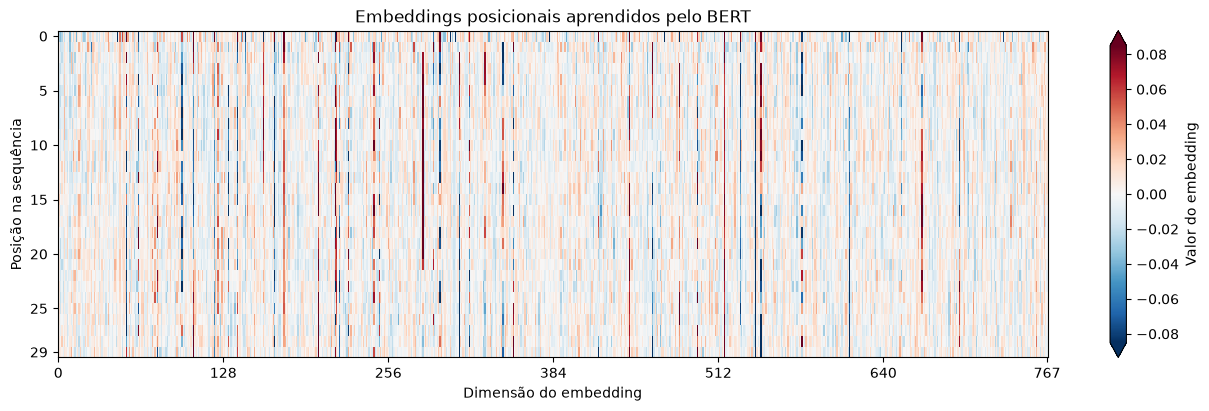

In [12]:
# para usar nos values max/min do heatmap, centralizando o branco em 0 e saturar a cor nos extremos.
color_limit = np.percentile(np.abs(position_embeddings_30), 99)

fig, ax = plt.subplots(figsize=(12, 4), layout="constrained")
heatmap = ax.imshow(position_embeddings_30, aspect="auto", interpolation="nearest", cmap="RdBu_r", vmin=-color_limit, vmax=color_limit)
ax.set(title="Embeddings posicionais aprendidos pelo BERT", xlabel="Dimensão do embedding", ylabel="Posição na sequência", xticks=[0, 128, 256, 384, 512, 640, 767], yticks=[0, 5, 10, 15, 20, 25, 29])
fig.colorbar(heatmap, ax=ax, label="Valor do embedding", extend="both")
plt.show()

A maior parte do heatmap tem tons claros, i.e., próximos de 0. Algumas dimensões se destacam como faixas verticais, com valores mais intensos e de mesmo sinal em várias posições (e.g. dim ~520). Em outras, a cor muda ao percorrer as linhas, indicando mudanças de magnitude ou de sinal. Mas nesse recorte não teve um padrão de repetição evidente.

---

#### 4. Implemente, utilizando operações com tensores do TensorFlow, o mecanismo de codificação posicional senoidal (*Sinusoidal Positional Encoding*), definido por:

$$
PE(pos, 2i) = \sin\left(\frac{pos}{10000^{2i/d_{\mathrm{model}}}}\right)
\tag{1}
$$

$$
PE(pos, 2i+1) = \cos\left(\frac{pos}{10000^{2i/d_{\mathrm{model}}}}\right)
\tag{2}
$$

#### Em que $pos$ representa a posição do token, $i$ representa o índice da dimensão e $d_{\mathrm{model}}$ é a dimensão das representações. Gere uma matriz para pelo menos 50 posições, utilizando $d_{\mathrm{model}} = 768$, e apresente seu formato (dimensões).

In [13]:
def sinusoidal_encoding(num_positions, d_model, start_position=0):
    positions = tf.range(start_position, start_position + num_positions)
    pos = tf.cast(positions[:, tf.newaxis], tf.float32)
    dim = tf.range(d_model)[tf.newaxis, :]

    par = (dim // 2) * 2
    expoente = tf.cast(par, tf.float32) / tf.cast(d_model, tf.float32)
    angulos = pos / tf.pow(10000.0, expoente)
    return tf.where(dim % 2 == 0, tf.sin(angulos), tf.cos(angulos))


num_positions = 50
d_model = 768
pe = sinusoidal_encoding(num_positions, d_model)
print("Formato da codificação posicional senoidal:", tuple(pe.shape))

Formato da codificação posicional senoidal: (50, 768)


---

#### 5. Gere um heatmap da matriz senoidal implementada e compare visualmente o resultado com o mapa de calor das representações aprendidas do BERT. Comente uma semelhança e uma diferença entre as duas estratégias.

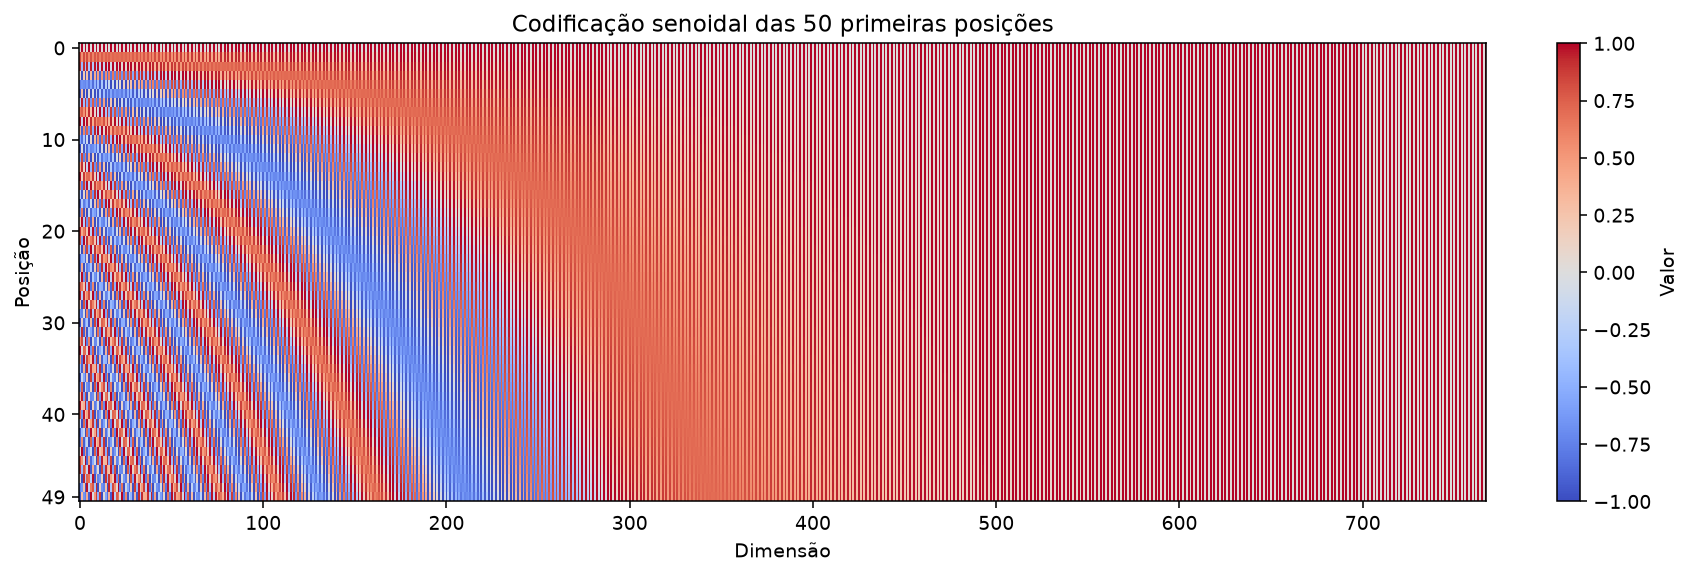

In [14]:
fig, ax = plt.subplots(figsize=(12, 4), dpi=140, layout="constrained")
heatmap = ax.imshow(pe.numpy(), aspect="auto", interpolation="nearest", cmap="coolwarm", vmin=-1, vmax=1)
ax.set(title="Codificação senoidal das 50 primeiras posições", xlabel="Dimensão", ylabel="Posição", yticks=[0, 10, 20, 30, 40, 49])
fig.colorbar(heatmap, ax=ax, label="Valor")

plt.show()

Matriz senoidal: (30, 768)
Matriz BERT: (30, 768)


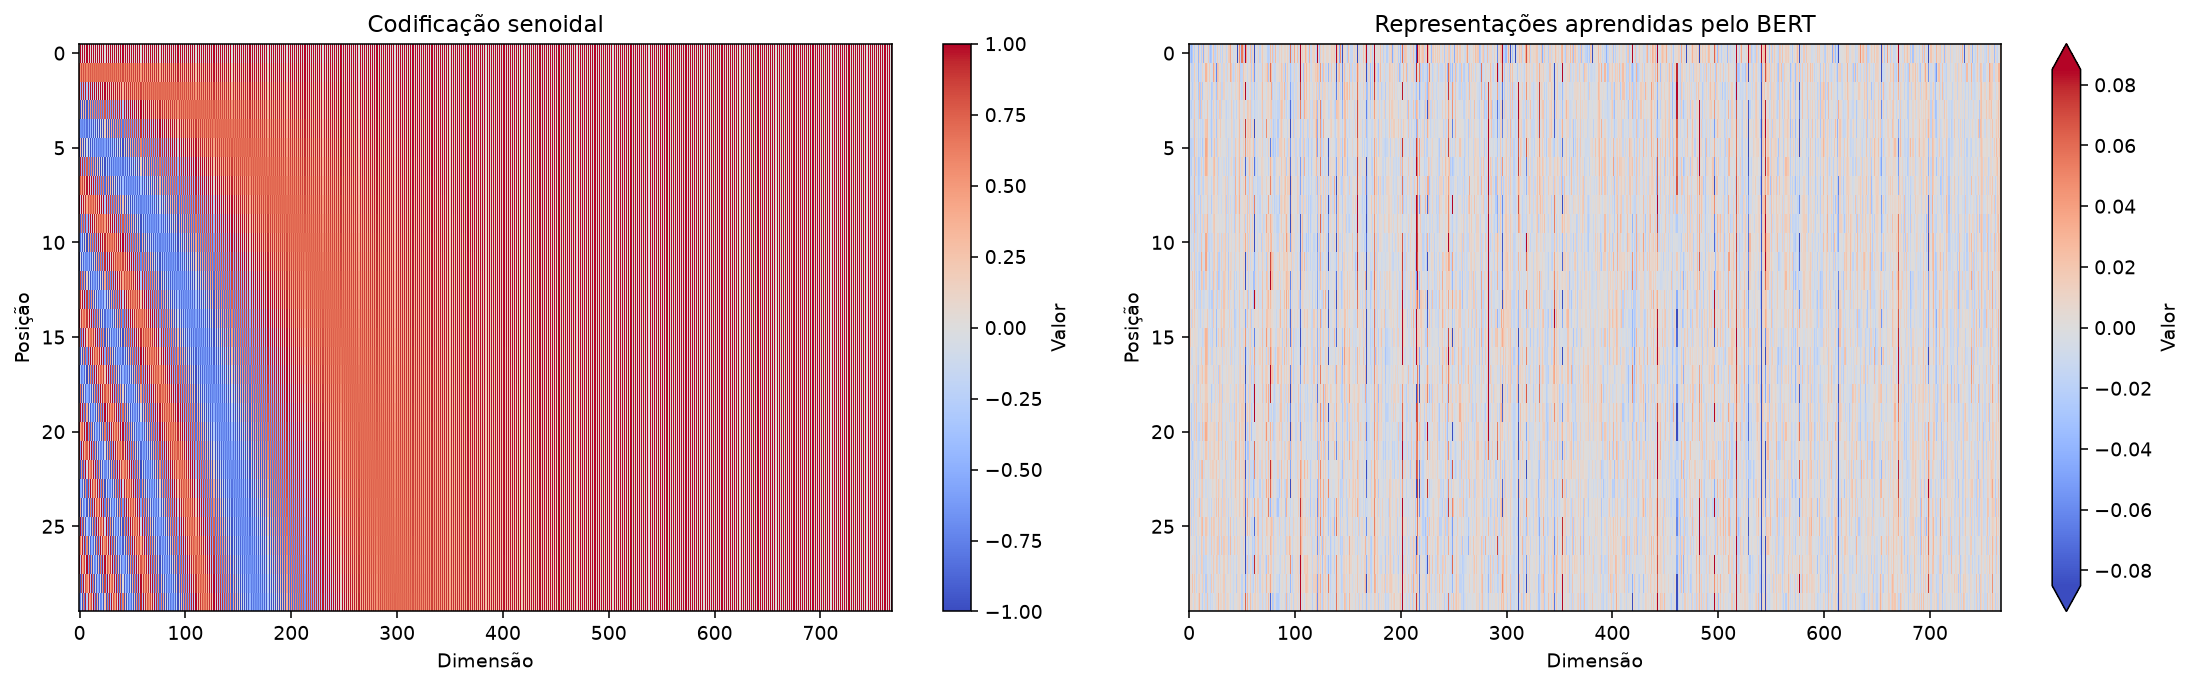

In [15]:
senoidal = np.asarray(pe)[:30]
aprendida = position_embeddings_30

print("Matriz senoidal:", senoidal.shape)
print("Matriz BERT:", aprendida.shape)

fig, axes = plt.subplots(1, 2, figsize=(16, 5), dpi=140)

im1 = axes[0].imshow(senoidal, aspect="auto", interpolation="nearest", cmap="coolwarm", vmin=-1, vmax=1)
axes[0].set_title("Codificação senoidal")
axes[0].set_xlabel("Dimensão")
axes[0].set_ylabel("Posição")
fig.colorbar(im1, ax=axes[0], label="Valor")
im2 = axes[1].imshow(aprendida, aspect="auto", interpolation="nearest", cmap="coolwarm", vmin=-color_limit, vmax=color_limit)
axes[1].set_title("Representações aprendidas pelo BERT")
axes[1].set_xlabel("Dimensão")
axes[1].set_ylabel("Posição")
fig.colorbar(im2, ax=axes[1], label="Valor", extend="both")

plt.tight_layout()
plt.show()

**Semelhança:** Nos 2 mapas, algumas dimensões mantem uma cor parecida ao longo de várias posições, formando faixas verticais.

**Diferença:** Na codificação senoidal, as oscilações seguem um padrão regular e ficam mais lentas da esquerda para a direita. No BERT, as variações aparecem de forma mais irregular, sem uma progressão de frequências visível.

---

### Configurações experimentais para o enunciado 6

| Experimento | Posições avaliadas | $d_{\mathrm{model}}$ da codificação senoidal | Variável alterada |
|---|---|---|---|
| Referência (baseline) | 462–511 | 768 | Nenhuma |
| B: Dimensionalidade | 462–511 | 256, 768 e 1536 | Dimensionalidade |
| J: Posições além do limite do BERT | 512-561 | 768 | Posição inicial da janela |
| B + J: Experimento combinado | 512-561 | 256, 768 e 1536 | Dimensionalidade e posição inicial |

#### No experimento J, comparamos a codificação senoidal com os embeddings aprendidos do BERT na faixa 462-511. Na faixa 512-561, observamos apenas a codificação senoidal, já que a tabela do BERT termina no índice 511. No experimento B e no combinado, a comparação entre dimensões é feita entre codificações senoidais.

#### 6. Configuração baseline

O baseline é a codificação senoidal das 50 posições consecutivas de **462 a 511**, com dimensão **768**. A janela termina no último índice da tabela posicional do BERT, então isso permite usar o mesmo intervalo para comparar as duas representações e, no experimento J, deslocar a janela para as 50 posições seguintes.

Formato da referência senoidal: (50, 768)


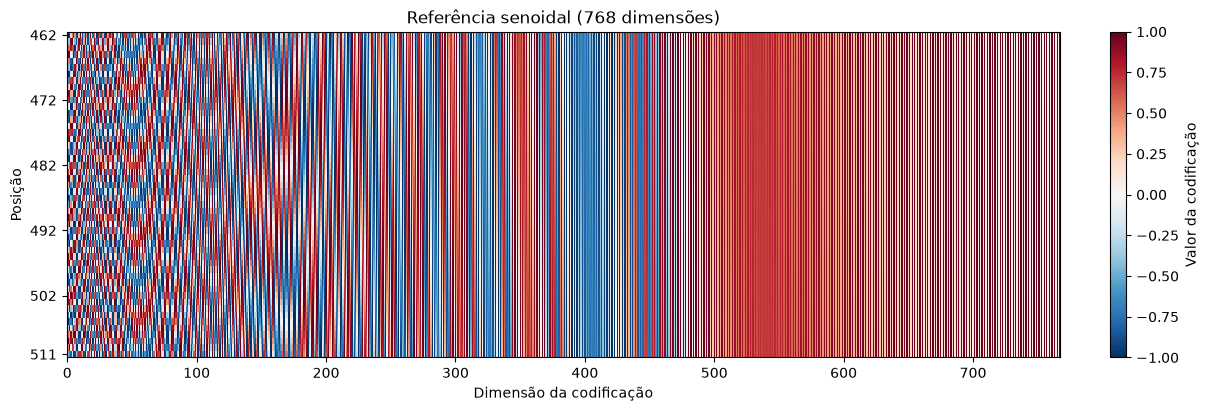

In [16]:
baseline_start = 462
baseline_length = 50
baseline_d_model = 768
baseline_end = baseline_start + baseline_length - 1

baseline_pe = sinusoidal_encoding(baseline_length, baseline_d_model, start_position=baseline_start)
print("Formato da referência senoidal:", tuple(baseline_pe.shape))

fig, ax = plt.subplots(figsize=(12, 4), layout="constrained")
heatmap = ax.imshow(baseline_pe.numpy(), aspect="auto", interpolation="nearest", origin="upper",
                    extent=(-0.5, baseline_d_model - 0.5, baseline_end + 0.5, baseline_start - 0.5), cmap="RdBu_r", vmin=-1, vmax=1)
ax.set(title="Referência senoidal (768 dimensões)", xlabel="Dimensão da codificação", ylabel="Posição", yticks=[462, 472, 482, 492, 502, 511])
fig.colorbar(heatmap, ax=ax, label="Valor da codificação")

plt.show()

No baseline, as colunas mais a esquerda mudam de cor várias vezes ao percorrer as posições, e à direita muitas colunas mantem quase a mesma cor ao longo da janela, formando algumas faixas verticais, indicando que essa codificação combina tanto frequências rápidas quanto lentas.



#### 6. B) Dimensionalidade. Como diferentes valores de $d_{\mathrm{model}}$ afetam as representações posicionais senoidais? Compare pelo menos três dimensões e observe as mudanças nos mapas de calor e nos padrões de variação das codificações. Para este experimento, analise as representações senoidais independentemente dos embeddings do BERT.

256 dimensões: (50, 256)
768 dimensões: (50, 768)
1536 dimensões: (50, 1536)


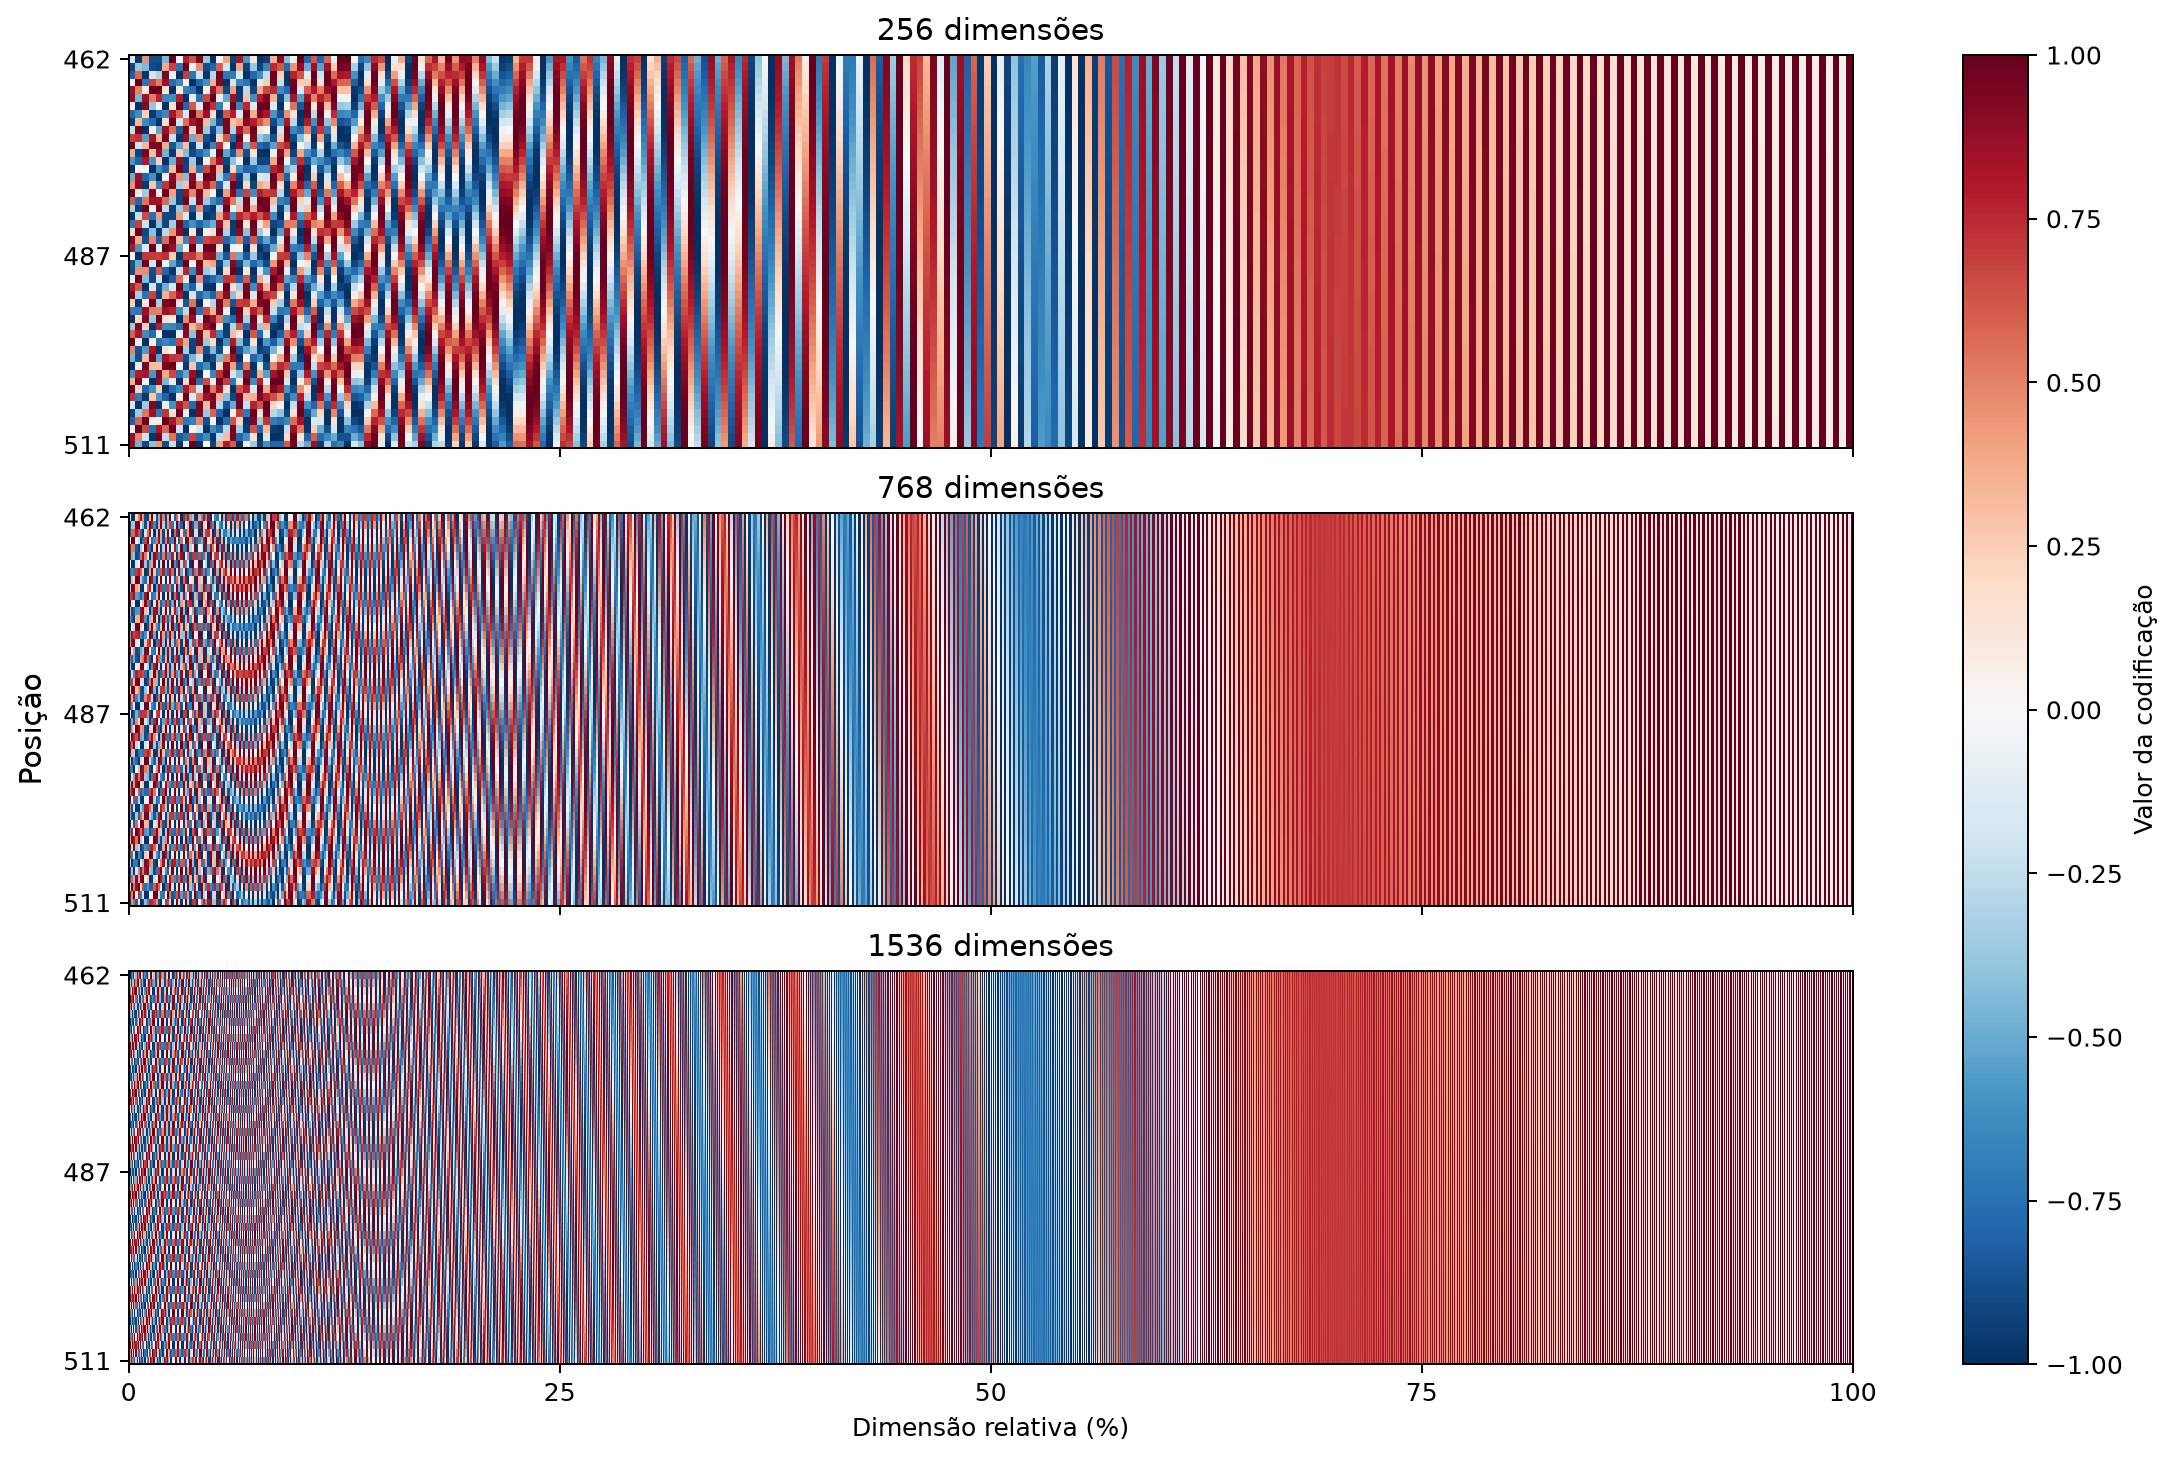

In [17]:
dimensions_b = (256, baseline_d_model, 1536)
encodings_b = {baseline_d_model: baseline_pe}

for width in (256, 1536):
    encodings_b[width] = sinusoidal_encoding(baseline_length, width, start_position=baseline_start)

fig, axes = plt.subplots(3, 1, figsize=(12, 8), dpi=180, layout="constrained", sharex=True, sharey=True)
for ax, width in zip(axes, dimensions_b):
    matrix = encodings_b[width]
    print(f"{width} dimensões: {tuple(matrix.shape)}")
    heatmap = ax.imshow(matrix.numpy(), aspect="auto", interpolation="nearest", origin="upper",
                        extent=(0, 100, baseline_end + 0.5, baseline_start - 0.5), cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set(title=f"{width} dimensões", yticks=[baseline_start, baseline_start + 25, baseline_end])

axes[-1].set(xlabel="Dimensão relativa (%)", xticks=[0, 25, 50, 75, 100])
fig.supylabel("Posição")
fig.colorbar(heatmap, ax=axes, label="Valor da codificação")
plt.show()

Mantemos as posições de **462 a 511**, a fórmula e a escala de cores de **−1 a 1**. O eixo horizontal mostra a dimensão em porcentagem, para comparar regiões equivalentes, já que os vetores de posição tem tamanhos diferentes.

Nos 3 mapas, as colunas à esquerda mudam de cor mais rápido ao longo das posições e à direita, as cores variam pouco de uma linha para a outra. Conforme passamos de 256 para 768 e 1536 dimensões, as faixas ficam mais finas e o padrão geral se mantém.

Isso acontece porque cada frequência ocupa um par de colunas, uma de seno e uma de cosseno, então temos **128, 384 e 768 pares**, respectivamente. Aumentar a dimensão acrescenta frequências intermediárias, enquanto a transição de oscilações rápidas para lentas continua visível nos 3 mapas.


#### 6. J) Generalização para posições não observadas. Como as representações posicionais senoidais e aprendidas se comportam para posições além daquelas consideradas inicialmente? Gere representações senoidais para posições maiores que o limite da tabela de posições aprendidas do BERT e compare os padrões obtidos. Discuta a possibilidade de gerar representações para posições não observadas durante o treinamento, destacando que a disponibilidade dessas codificações não garante, por si só, que um modelo Transformer treinado em sequências menores consiga processar sequências mais longas adequadamente.

Senoidal além do limite (512-561): (50, 768)
Recorte do BERT (462-511): (50, 768)


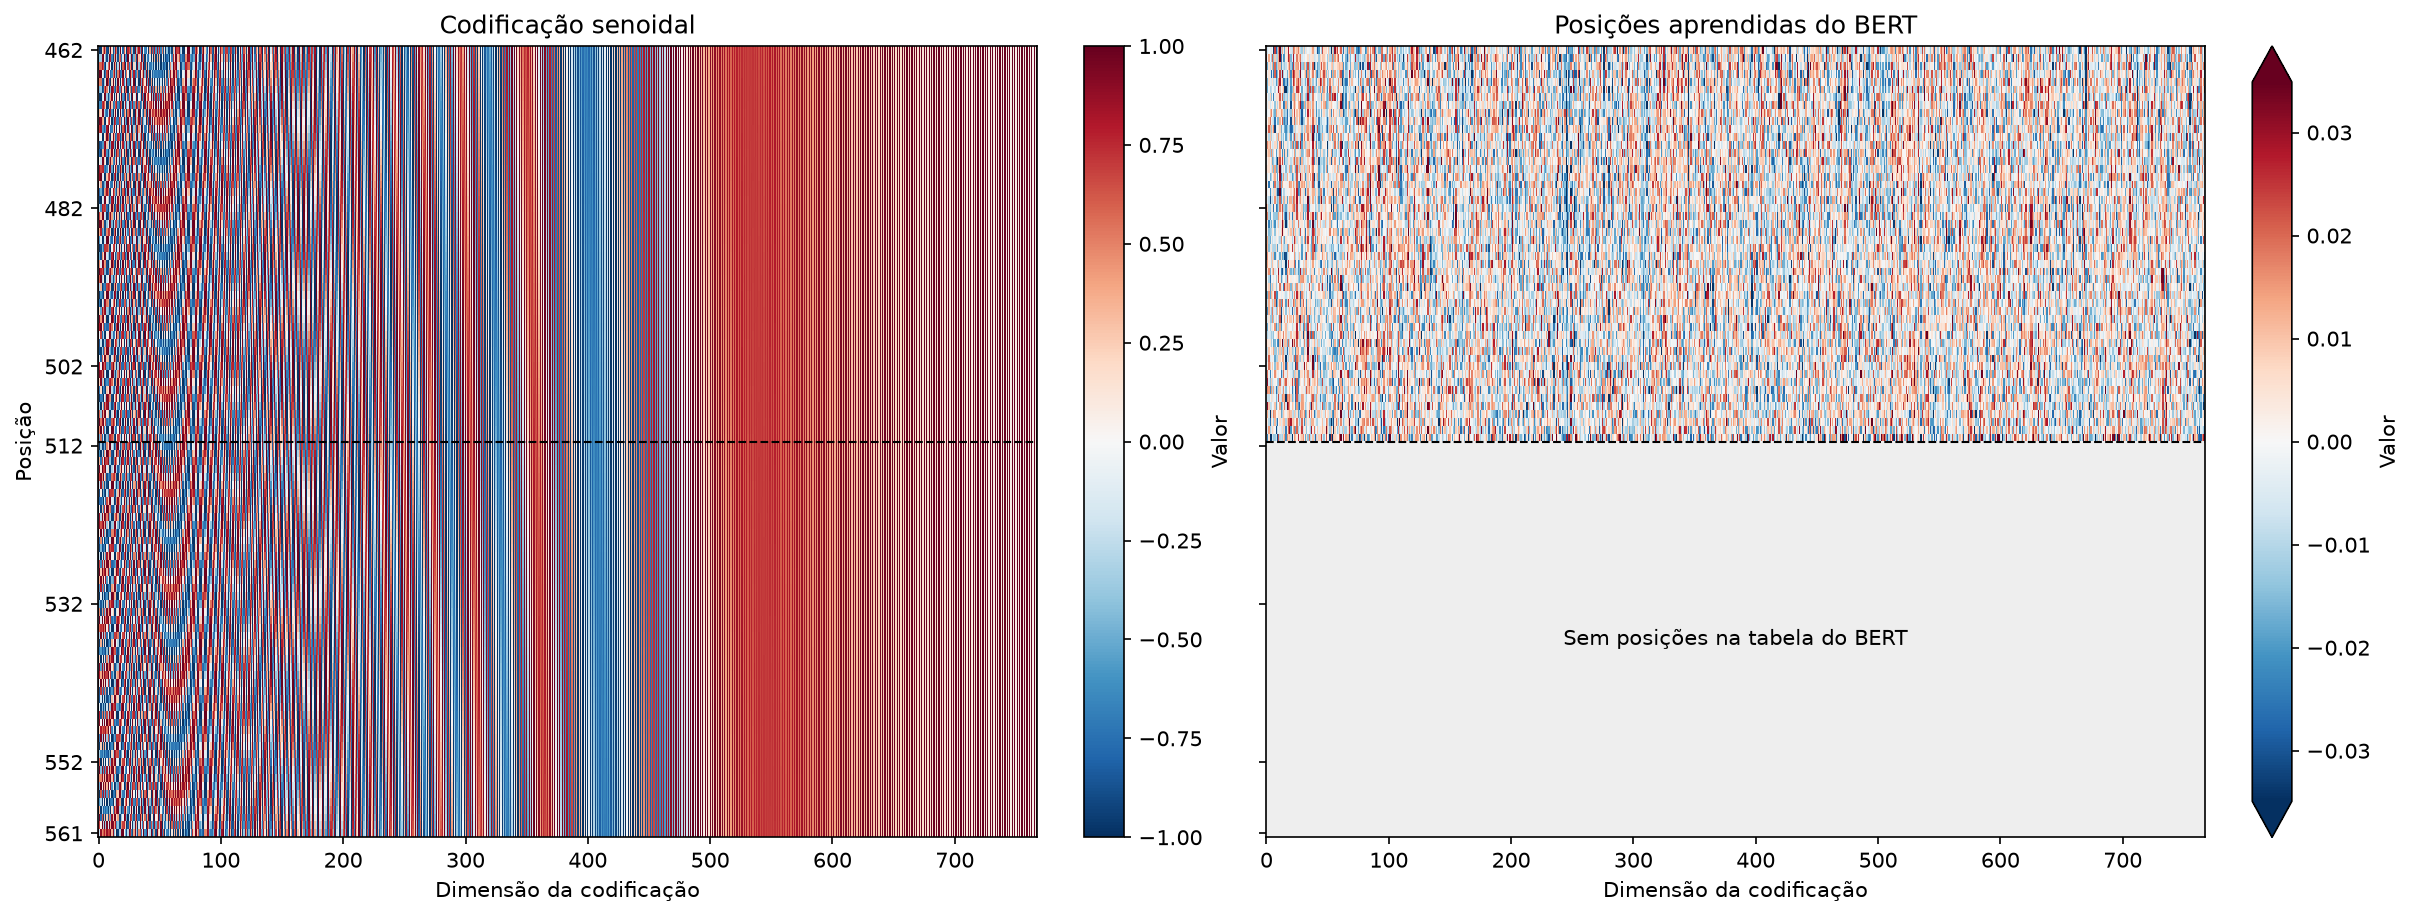

In [18]:
j_start = position_table.shape[0]
j_end = j_start + baseline_length - 1

pe_j = sinusoidal_encoding(baseline_length, baseline_d_model, start_position=j_start)
j_senoidal = tf.concat([baseline_pe, pe_j], axis=0).numpy()
j_bert = position_table[baseline_start:j_start]
j_bert_limit = np.percentile(np.abs(j_bert), 99)

print(f"Senoidal além do limite ({j_start}-{j_end}): {tuple(pe_j.shape)}")
print(f"Recorte do BERT ({baseline_start}-{baseline_end}): {j_bert.shape}")

fig, (ax_senoidal, ax_bert) = plt.subplots(1, 2, figsize=(16, 6), dpi=150, sharex=True, sharey=True, layout="constrained")
dimension_limits = (-0.5, baseline_d_model - 0.5)
boundary = j_start - 0.5

im_senoidal = ax_senoidal.imshow(j_senoidal, aspect="auto", interpolation="nearest", origin="upper",
                                 extent=(*dimension_limits, j_end + 0.5, baseline_start - 0.5), cmap="RdBu_r", vmin=-1, vmax=1)
im_bert = ax_bert.imshow(j_bert, aspect="auto", interpolation="nearest", origin="upper",
                         extent=(*dimension_limits, boundary, baseline_start - 0.5), cmap="RdBu_r", vmin=-j_bert_limit, vmax=j_bert_limit)

ax_bert.axhspan(boundary, j_end + 0.5, color="#eeeeee")
ax_bert.text((baseline_d_model - 1) / 2, (j_start + j_end) / 2, "Sem posições na tabela do BERT", ha="center", va="center")

for ax, title in ((ax_senoidal, "Codificação senoidal"), (ax_bert, "Posições aprendidas do BERT")):
    ax.axhline(boundary, color="black", linestyle="--", linewidth=1)
    ax.set(title=title, xlabel="Dimensão da codificação")

ax_senoidal.set(ylabel="Posição", ylim=(j_end + 0.5, baseline_start - 0.5), 
                yticks=[baseline_start, baseline_start + 20, baseline_start + 40, j_start, j_start + 20, j_start + 40, j_end])
fig.colorbar(im_senoidal, ax=ax_senoidal, label="Valor")
fig.colorbar(im_bert, ax=ax_bert, label="Valor", extend="both")

plt.show()

Mantemos **768 dimensões** e deslocamos a janela de 50 posições de **462-511** para **512-561**. De 462 a 511, o mapa da senoidal mostra oscilações rápidas à esquerda e mais lentas à direita. No mesmo intervalo, o BERT apresenta variações mais irregulares entre as posições e dimensões. Na passagem para 512, o padrão senoidal continua sem uma mudança abrupta, pois a mesma fórmula é aplicada nas duas janelas. O BERT tem uma tabela aprendida com índices de 0 a 511, então o gráfico deixa a segunda janela sem valores. O resultado mostra que podemos **calcular vetores posicionais senoidais** para índices além do limite do BERT. Para saber se um Transformer treinado com sequências mais curtas realmente aproveitaria esses vetores, seria preciso avaliar o desempenho do modelo em uma tarefa com sequências mais longas.

#### 6. B + J) Mudando dimensão e posições não observadas. O que muda ao variar a dimensão nas posições além do limite do BERT?

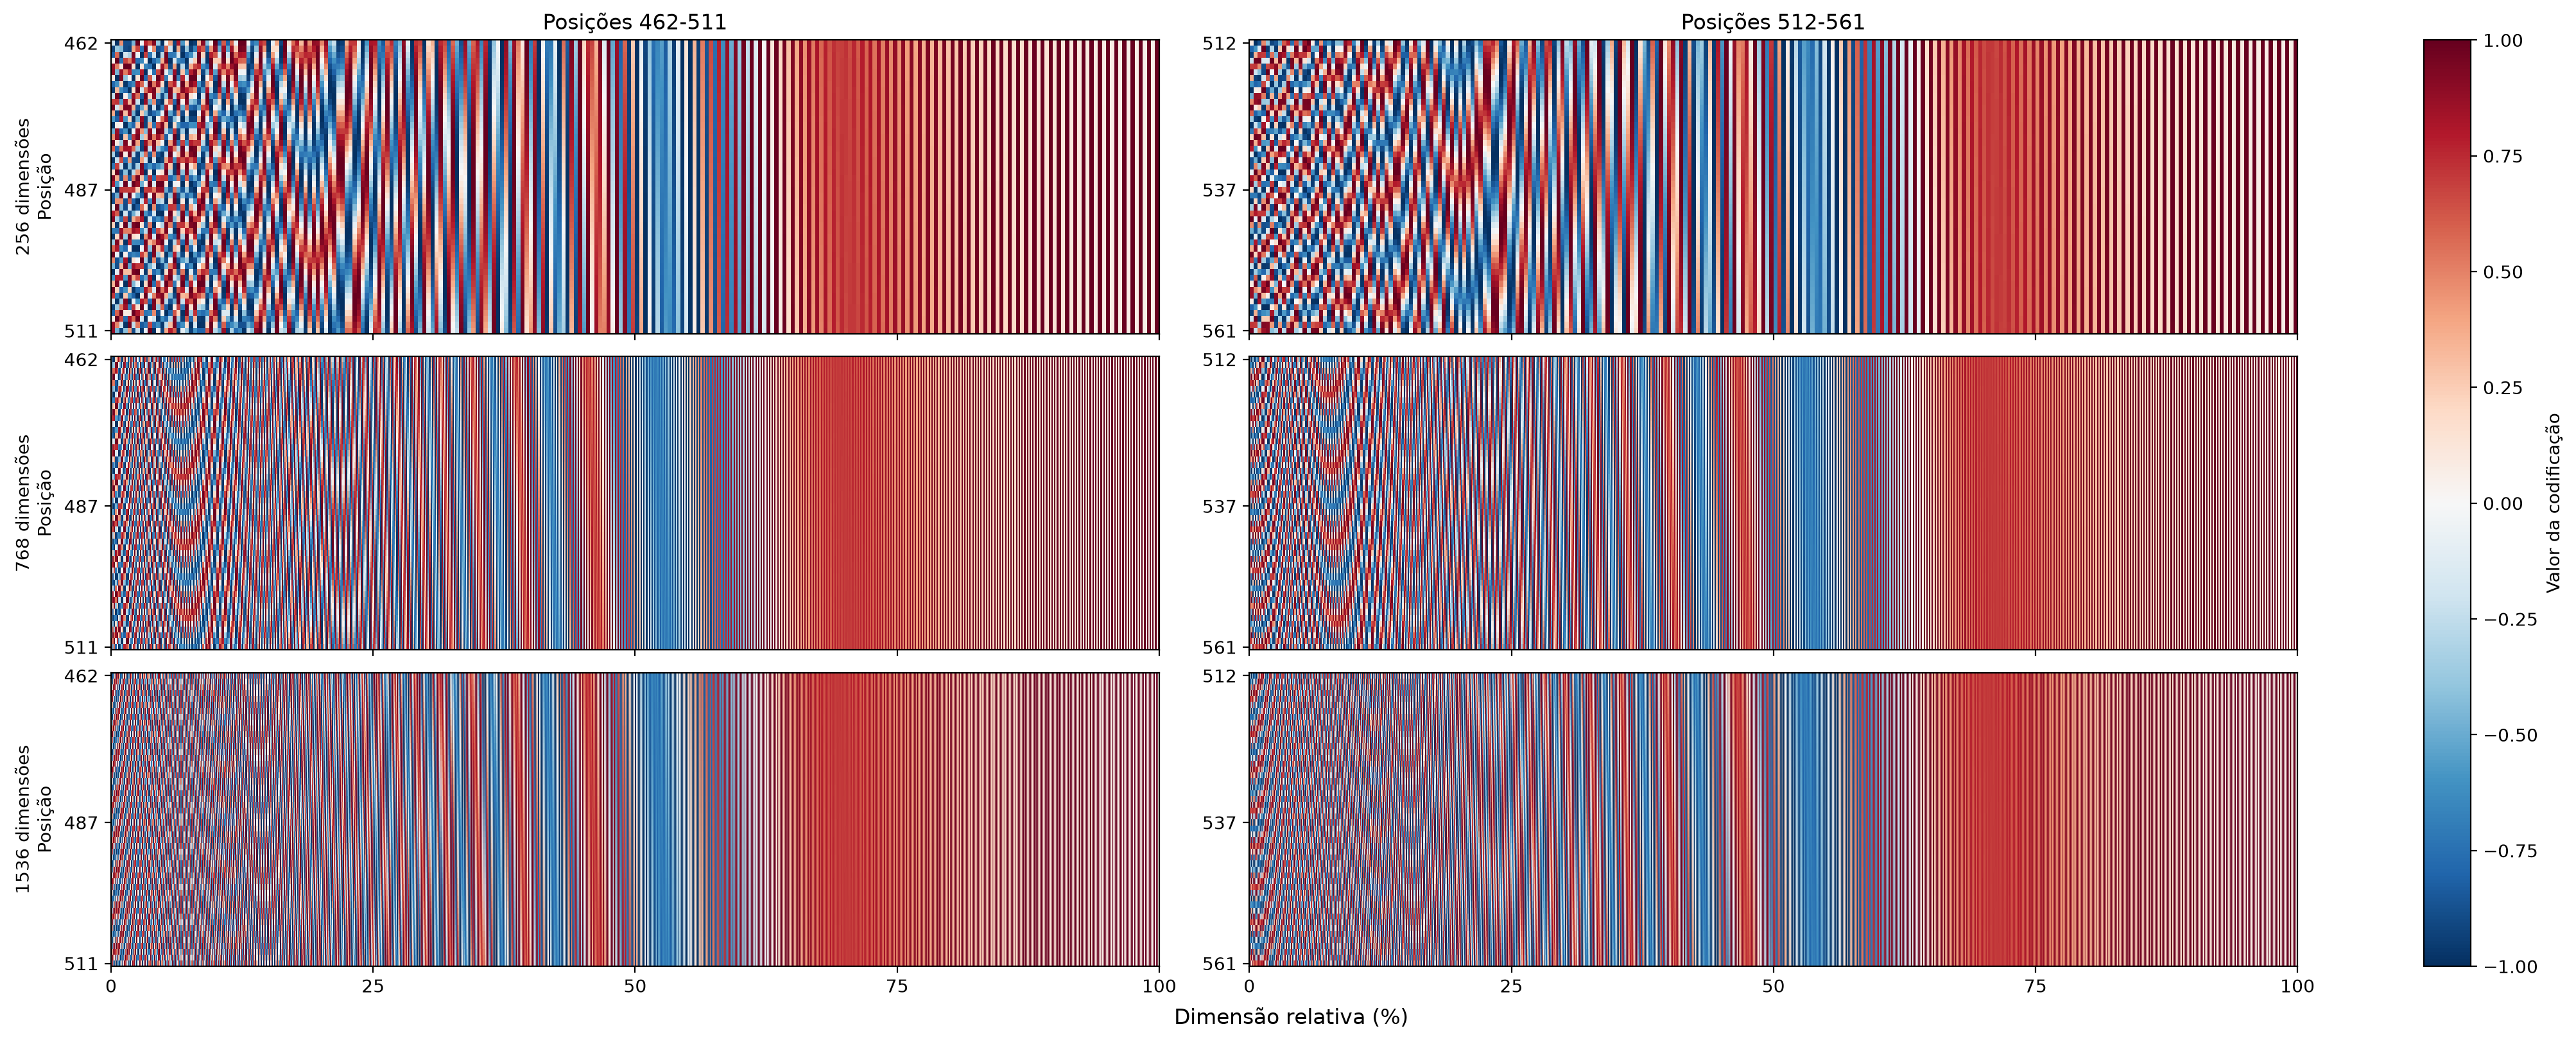

In [19]:
encodings_bj = {baseline_d_model: pe_j}

for width in dimensions_b:
    if width != baseline_d_model:
        encodings_bj[width] = sinusoidal_encoding(baseline_length, width, start_position=j_start)

windows = ((baseline_start, baseline_end, encodings_b), (j_start, j_end, encodings_bj))

fig, axes = plt.subplots(len(dimensions_b), 2, figsize=(20, 8), dpi=200, layout="constrained", sharex=True, sharey="col")
for column, (start, end, encodings) in enumerate(windows):
    axes[0, column].set_title(f"Posições {start}-{end}")

    for row, width in enumerate(dimensions_b):
        ax = axes[row, column]
        heatmap = ax.imshow(encodings[width].numpy(), aspect="auto", interpolation="nearest",
                            origin="upper", extent=(0, 100, end + 0.5, start - 0.5), cmap="RdBu_r", vmin=-1, vmax=1)
        
        ax.set(yticks=[start, start + baseline_length // 2, end])
        if column == 0:
            ax.set_ylabel(f"{width} dimensões\nPosição")

axes[-1, 0].set(xticks=[0, 25, 50, 75, 100])
fig.supxlabel("Dimensão relativa (%)")
fig.colorbar(heatmap, ax=axes, label="Valor da codificação")

plt.show()

**Ao variar a dimensão**, as faixas ficam mais finas nas duas janelas, porque tem mais pares de seno e cosseno e frequências intermediárias. Mas o padrão geral continua, com as oscilações mais rápidas nas primeiras dimensões e mais lentas nas últimas.

**Ao deslocar a janela**, algumas faixas mudam de cor nas mesmas linhas relativas. Para uma dimensão fixa, avançar 50 posições muda a fase de cada senoide, i.e., o ponto em que observamos o ciclo. A frequência de cada par continua a mesma. Assim, o efeito da dimensionalidade observado no baseline também aparece além da posição 511.